In [158]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [159]:
DATA_PATH = Path("../data/raw")

columns =  (
    ["engine_id","cycle"] +
    [f"setting_{i}" for i in range(1,4)] +
    [f"sensor_{i}" for i in range(1,22)]
)

df = pd.read_csv(DATA_PATH / "train_FD001.txt"
                 ,sep=r"\s+",header=None
                 )

df.columns = columns
df.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [160]:
df["max_cycle"] = df.groupby("engine_id")["cycle"].transform("max")
df["RUL"] = df["max_cycle"] - df["cycle"]

In [161]:
print(df.shape)
print(df[["engine_id", "cycle", "RUL"]].head())

(20631, 28)
   engine_id  cycle  RUL
0          1      1  191
1          1      2  190
2          1      3  189
3          1      4  188
4          1      5  187


In [162]:
constant_features = [
    "setting_3",
    "sensor_1",
    "sensor_5",
    "sensor_10",
    "sensor_16",
    "sensor_18",
    "sensor_19"
]

exclude_cols = constant_features + [
    "engine_id",
    "cycle",
    "max_cycle",
    "RUL"
]

X = df.drop(columns=exclude_cols)
y = df["RUL"]

print("Features:", X.shape)
print("Target:", y.shape)
print("Remaining constant features:", X.columns[X.nunique() == 1].tolist())

Features: (20631, 17)
Target: (20631,)
Remaining constant features: []


In [96]:
from sklearn.model_selection import train_test_split

engine_ids = df["engine_id"].unique()

train_engines,val_engines = train_test_split(
    engine_ids,test_size=0.2,random_state=42
)

train_mask = df["engine_id"].isin(train_engines)
val_mask = df["engine_id"].isin(val_engines)

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

print(len(train_engines),len(val_engines))
print((X_train.shape),(X_val.shape))
print(set(train_engines).intersection(val_engines))


80 20
(16561, 17) (4070, 17)
set()


In [97]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,root_mean_squared_error

model = LinearRegression()
model.fit(X_train,y_train)

y_pred = model.predict(X_val)


mae = mean_absolute_error(y_val, y_pred)
rmse = root_mean_squared_error(y_val, y_pred)
print(mae,rmse)



30.111252539999462 38.13253480127496


In [98]:
base_model = ({
    "model": "LinearRegression",
    "MAE":mae,
    "RMSE":rmse
})


base_model

{'model': 'LinearRegression',
 'MAE': 30.111252539999462,
 'RMSE': 38.13253480127496}

In [99]:
error_df = pd.DataFrame({
    "actual_RUL":y_val,
    "predicted":y_pred
})

error_df["error"] = (
    error_df["actual_RUL"] - error_df["predicted"]
)

error_df["absolute_error"] = error_df["error"].abs()
error_df.sort_values("absolute_error",ascending=False).head(10)



,actual_RUL,predicted,error,absolute_error
16885,266,102.705975,163.294025,163.294025
16895,256,99.760358,156.239642,156.239642
16896,255,102.578924,152.421076,152.421076
16897,254,105.369723,148.630277,148.630277
16888,263,114.472897,148.527103,148.527103
16886,265,117.256944,147.743056,147.743056
16891,260,113.276696,146.723304,146.723304
16887,264,117.714304,146.285696,146.285696
16889,262,115.793771,146.206229,146.206229
16893,258,114.890042,143.109958,143.109958


In [100]:
# This cell is just for practice and they not effect the whole project and clean code criteria


# arr = [1,2,3,4,5,6,7,24,35654,845354,864,-4,-5435,4234]

# def second_higherst(arr):
#     unique = sorted(set(arr),reverse=True)
#     if len(unique) < 2:
#         return None
#     else:
#         return unique[-2]
# second_higherst(arr)    

In [101]:


error_df["RUL_range"] = pd.cut(
    error_df["actual_RUL"],
    bins=[-1, 50, 100, 150, 200, 250, 400],
    labels=["0-50", "51-100", "101-150",
            "151-200", "201-250", "251+"]
)

error_df.groupby("RUL_range", observed=True).agg(
    observations=("actual_RUL", "size"),
    MAE=("absolute_error", "mean"),
    mean_error=("error", "mean")
)


,observations,MAE,mean_error
RUL_range,,,
0-50,1020,23.224666,-11.848196
51-100,1000,31.765883,-30.326576
101-150,984,22.203536,-7.575645
151-200,673,29.629719,25.541132
201-250,348,59.391374,59.391374
251+,45,103.121732,103.121732


In [102]:
(error_df["absolute_error"] < 0).sum()

np.int64(0)

In [103]:
from sklearn.metrics import r2_score

r2 = r2_score(y_val, y_pred)

print("R2 Score:", r2)

R2 Score: 0.6626376008508181


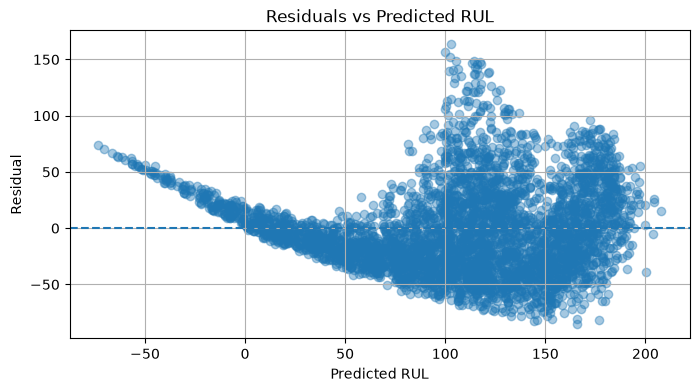

In [104]:
import matplotlib.pyplot as plt

residuals = y_val - y_pred

plt.figure(figsize=(8, 4))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted RUL")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted RUL")
plt.grid()
plt.show()

In [105]:
error_df["engine_id"] = df.loc[X_val.index,"engine_id"].values

In [106]:
X_val.index

Index([    0,     1,     2,     3,     4,     5,     6,     7,     8,     9,
       ...
       18505, 18506, 18507, 18508, 18509, 18510, 18511, 18512, 18513, 18514],
      dtype='int64', length=4070)

In [107]:
df["engine_id"].nunique()

100

In [108]:
engine_errors = (
    error_df.groupby("engine_id").agg(
        observations = ("actual_RUL","size"),
        MAE= ("absolute_error","mean"),
        mean_error = ("error","mean")
    ).sort_values("MAE",ascending=False)
)

engine_errors.head(10)

,observations,MAE,mean_error
engine_id,,,
84,267,51.645783,49.928458
45,158,45.669942,-43.614051
74,166,36.712456,-34.877088
1,192,33.656470,-28.883966
31,234,32.865833,-18.764780
78,231,31.778799,-22.723100
46,256,31.778653,-5.475178
5,269,30.881627,10.039355
81,240,30.836388,20.088170


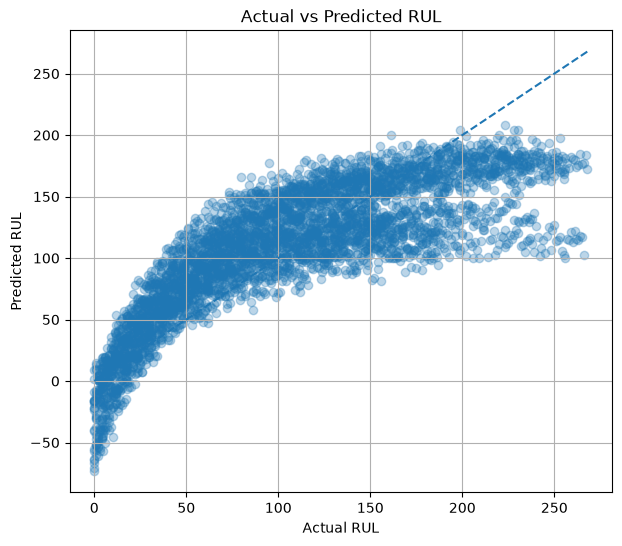

In [109]:
plt.figure(figsize=(7, 6))

plt.scatter(y_val, y_pred, alpha=0.3)

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")
plt.grid()
plt.show()

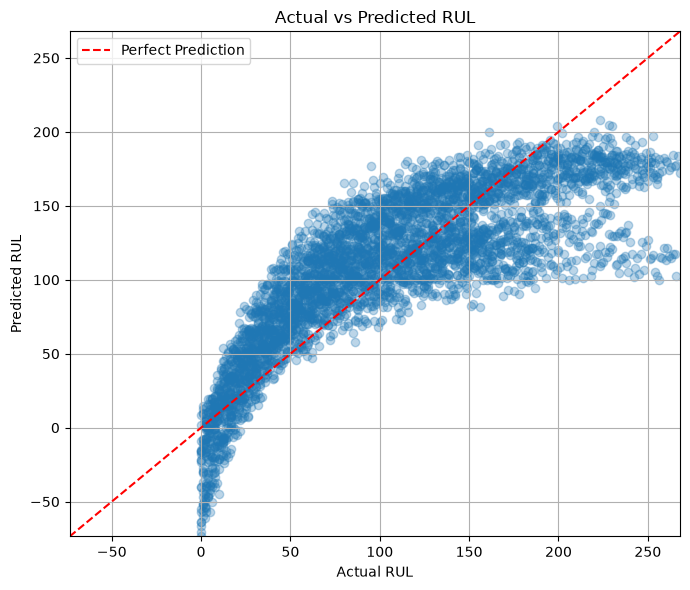

In [110]:
# Find common minimum and maximum
lower = min(y_val.min(), y_pred.min())
upper = max(y_val.max(), y_pred.max())

plt.figure(figsize=(7, 6))

# Actual vs Predicted
plt.scatter(y_val, y_pred, alpha=0.3)

# Perfect prediction reference line
plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle='--',
    color='red',
    label='Perfect Prediction'
)

# Keep both axes on the same scale
plt.xlim(lower, upper)
plt.ylim(lower, upper)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL")

plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [111]:
from sklearn.ensemble import RandomForestRegressor

Rf = RandomForestRegressor(n_estimators=200,random_state=42,max_depth=None, min_samples_split=2,min_samples_leaf=1,max_features=1,criterion="squared_error",n_jobs=-1,bootstrap=True,oob_score=True)

Rf.fit(X_train,y_train)
Rf_pred = Rf.predict(X_val)
print(f"oob Score: {Rf.oob_score_}")


oob Score: 0.6123136332367453


In [112]:
from sklearn.metrics import (mean_absolute_error,root_mean_squared_error,r2_score)
rf_MAE = mean_absolute_error(y_val,Rf_pred)
rf_RMSE = root_mean_squared_error(y_val,Rf_pred)
rf_r2 = r2_score(y_val,Rf_pred)
print("Random Forest MAE:", rf_MAE)
print("Random Forest RMSE:", rf_RMSE)
print("Random Forest R2:", rf_r2)

Random Forest MAE: 25.985964373464373
Random Forest RMSE: 35.346363513543885
Random Forest R2: 0.7101356502156886


In [113]:
comparison = pd.DataFrame({
    "model":["LinearRegression","RandomForestRegressor"],
    "MSE" : [mae,rf_MAE],
    "RMSE": [rmse,rf_RMSE],
    "R2": [r2,rf_r2]
})
comparison.head(2)

,model,MSE,RMSE,R2
0,LinearRegression,30.111253,38.132535,0.662638
1,RandomForestRegressor,25.985964,35.346364,0.710136


In [114]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    subsample=1.0,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_val)


In [115]:
gb_mae = mean_absolute_error(y_val, gb_pred)
gb_rmse = root_mean_squared_error(y_val, gb_pred)
gb_r2 = r2_score(y_val, gb_pred)

print("Gradient Boosting MAE:", gb_mae)
print("Gradient Boosting RMSE:", gb_rmse)
print("Gradient Boosting R2:", gb_r2)

Gradient Boosting MAE: 26.136164149112005
Gradient Boosting RMSE: 35.42507984119446
Gradient Boosting R2: 0.7088431572038687


In [116]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [mae, rf_MAE, gb_mae],
    "RMSE": [rmse, rf_RMSE, gb_rmse],
    "R2": [r2, rf_r2, gb_r2]
})

comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
1,Random Forest,25.985964,35.346364,0.710136
2,Gradient Boosting,26.136164,35.425080,0.708843
0,Linear Regression,30.111253,38.132535,0.662638


In [117]:
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=1,
    subsample=1.0,
    colsample_bytree=1.0,
    reg_lambda=1,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_val)

xgb_mae = mean_absolute_error(y_val, xgb_pred)
xgb_rmse = root_mean_squared_error(y_val, xgb_pred)
xgb_r2 = r2_score(y_val, xgb_pred)

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)
print("XGBoost R2:", xgb_r2)

XGBoost MAE: 26.03378677368164
XGBoost RMSE: 35.31844711303711
XGBoost R2: 0.7105933427810669


In [118]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    "MAE": [mae, rf_MAE, gb_mae, xgb_mae],
    "RMSE": [rmse, rf_RMSE, gb_rmse, xgb_rmse],
    "R2": [r2, rf_r2, gb_r2, xgb_r2]
})

comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
1,Random Forest,25.985964,35.346364,0.710136
3,XGBoost,26.033787,35.318447,0.710593
2,Gradient Boosting,26.136164,35.425080,0.708843
0,Linear Regression,30.111253,38.132535,0.662638


In [119]:
from lightgbm import LGBMRegressor

lgbm_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    num_leaves=7,
    min_child_samples=20,
    subsample=1.0,
    colsample_bytree=1.0,
    reg_lambda=0.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)

lgbm_pred = lgbm_model.predict(X_val)

lgbm_mae = mean_absolute_error(y_val, lgbm_pred)
lgbm_rmse = root_mean_squared_error(y_val, lgbm_pred)
lgbm_r2 = r2_score(y_val, lgbm_pred)

print("LightGBM MAE:", lgbm_mae)
print("LightGBM RMSE:", lgbm_rmse)
print("LightGBM R2:", lgbm_r2)

LightGBM MAE: 25.98844193386274
LightGBM RMSE: 35.2795986064987
LightGBM R2: 0.711229651802083


In [120]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost",
        "LGBMRegressor"
    ],
    "MAE": [mae, rf_MAE, gb_mae, xgb_mae,lgbm_mae],
    "RMSE": [rmse, rf_RMSE, gb_rmse, xgb_rmse,lgbm_rmse],
    "R2": [r2, rf_r2, gb_r2, xgb_r2,lgbm_r2]
})

comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
1,Random Forest,25.985964,35.346364,0.710136
4,LGBMRegressor,25.988442,35.279599,0.711230
3,XGBoost,26.033787,35.318447,0.710593
2,Gradient Boosting,26.136164,35.425080,0.708843
0,Linear Regression,30.111253,38.132535,0.662638


In [121]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svr_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10, epsilon=0.1)
)

svr_model.fit(X_train, y_train)

svr_pred = svr_model.predict(X_val)

svr_mae = mean_absolute_error(y_val, svr_pred)
svr_rmse = root_mean_squared_error(y_val, svr_pred)
svr_r2 = r2_score(y_val, svr_pred)

print("SVR MAE:", svr_mae)
print("SVR RMSE:", svr_rmse)
print("SVR R2:", svr_r2)

SVR MAE: 25.37258263181324
SVR RMSE: 35.24342836648424
SVR R2: 0.7118214691088263


In [122]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost",
        "LGBMRegressor",
        "SVR"
    ],
    "MAE": [mae, rf_MAE, gb_mae, xgb_mae,lgbm_mae,svr_mae],
    "RMSE": [rmse, rf_RMSE, gb_rmse, xgb_rmse,lgbm_rmse,svr_rmse],
    "R2": [r2, rf_r2, gb_r2, xgb_r2,lgbm_r2,svr_r2]
})

comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
5,SVR,25.372583,35.243428,0.711821
1,Random Forest,25.985964,35.346364,0.710136
4,LGBMRegressor,25.988442,35.279599,0.711230
3,XGBoost,26.033787,35.318447,0.710593
2,Gradient Boosting,26.136164,35.425080,0.708843
0,Linear Regression,30.111253,38.132535,0.662638


In [123]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        num_leaves=7,
        min_child_samples=20,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ),

    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.1)
    )
}

In [124]:
from sklearn.model_selection import GroupKFold

group_kfold = GroupKFold(n_splits=5)

groups_train = df.loc[train_mask,"engine_id"]

print("Training_rows:",len(X_train))
print("Unique Training Engines:",groups_train.nunique())

Training_rows: 16561
Unique Training Engines: 80


In [125]:
df["engine_id"].nunique()

100

In [126]:
import pandas as pd
from sklearn.model_selection import cross_validate

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=group_kfold,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "MAE_mean": -scores["test_MAE"].mean(),
        "MAE_std": scores["test_MAE"].std(),
        "RMSE_mean": -scores["test_RMSE"].mean(),
        "RMSE_std": scores["test_RMSE"].std(),
        "R2_mean": scores["test_R2"].mean(),
        "R2_std": scores["test_R2"].std()
    })

cv_comparison = pd.DataFrame(cv_results)

cv_comparison.sort_values("MAE_mean")

,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
5,SVR,30.960558,1.451769,44.471446,2.641359,0.591818,0.033445
4,LightGBM,31.901800,1.889059,44.623649,2.595096,0.588745,0.036372
2,Gradient Boosting,31.928672,1.883037,44.639020,2.623902,0.588455,0.036824
3,XGBoost,31.964312,1.883853,44.676338,2.579479,0.587776,0.036201
1,Random Forest,31.970497,2.028587,45.004166,2.682199,0.581724,0.037624
0,Linear Regression,35.377428,2.107273,46.382287,2.426103,0.556028,0.032049


In [127]:
fold_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=group_kfold,
        scoring=scoring,
        n_jobs=1
    )

    for fold in range(5):
        fold_results.append({
            "Model": name,
            "Fold": fold + 1,
            "MAE": -scores["test_MAE"][fold],
            "RMSE": -scores["test_RMSE"][fold],
            "R2": scores["test_R2"][fold]
        })

fold_comparison = pd.DataFrame(fold_results)

fold_comparison.pivot(
    index="Fold",
    columns="Model",
    values="MAE"
)

Model,Gradient Boosting,LightGBM,Linear Regression,Random Forest,SVR,XGBoost
Fold,,,,,,
1,33.730685,33.713851,36.927396,34.052167,32.773641,33.722527
2,29.179448,29.179614,33.262785,29.077112,29.835860,29.223497
3,34.319450,34.321901,38.233887,34.403285,32.686826,34.392460
4,30.918877,30.871129,32.724323,30.594986,29.966170,30.924986
5,31.494899,31.422508,35.738750,31.724937,29.540294,31.558088


In [128]:
fold_distribution = []

for fold, (_,val_idx) in enumerate(
    group_kfold.split(X_train,y_train,groups_train),
    start=1
):
    fold_y = y_train.iloc[val_idx]
    
    fold_distribution.append({
        "Fold": fold,
        "Rows": len(val_idx),
        "Unique_Engines": groups_train.iloc[val_idx].nunique(),
        "Mean_RUL": fold_y.mean(),
        "Median_RUL": fold_y.median(),
        "Min_RUL": fold_y.min(),
        "Max_RUL": fold_y.max()
    })
    
    
pd.DataFrame(fold_distribution)    

,Fold,Rows,Unique_Engines,Mean_RUL,Median_RUL,Min_RUL,Max_RUL
0,1,3311,16,109.263063,103.0,0,361
1,2,3303,16,108.639721,103.0,0,340
2,3,3310,16,108.366767,103.0,0,335
3,4,3319,16,107.923170,103.0,0,312
4,5,3318,16,107.699518,103.0,0,292


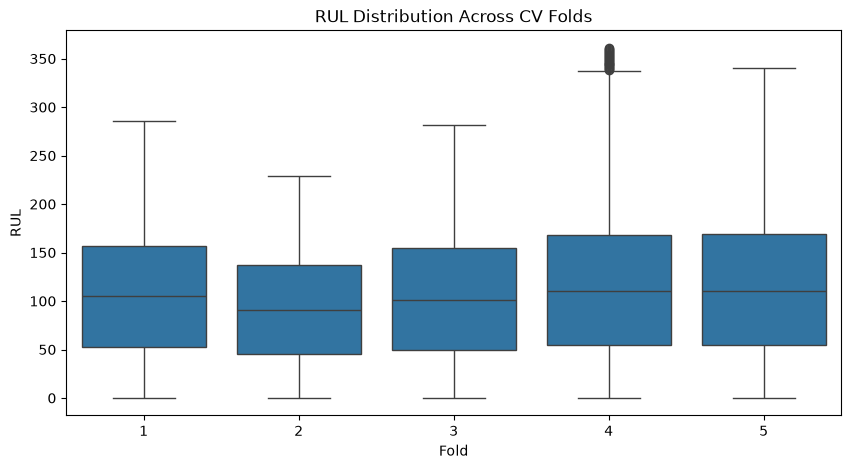

In [129]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=pd.DataFrame({
        "RUL": y_train,
        "Fold": [
            fold
            for fold, (_, val_idx) in enumerate(
                group_kfold.split(X_train, y_train, groups_train),
                start=1
            )
            for _ in val_idx
        ]
    }),
    x="Fold",
    y="RUL"
)

plt.title("RUL Distribution Across CV Folds")
plt.show()

In [130]:
from sklearn.model_selection import RandomizedSearchCV

svr_param_grid = {
    "svr__C": [1, 5, 10, 20, 50, 100],
    "svr__epsilon": [0.01, 0.1, 0.5, 1, 2],
    "svr__gamma": ["scale", "auto", 0.001, 0.01, 0.1]
}

svr_search = RandomizedSearchCV(
    estimator=svr_model,
    param_distributions=svr_param_grid,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=group_kfold,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

svr_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step..., SVR(C=10))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'svr__C': [1, 5, ...], 'svr__epsilon': [0.01, 0.1, ...], 'svr__gamma': ['scale', 'auto', ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a functi

In [131]:
print("Best Parameters:", svr_search.best_params_)
print("Best CV MAE:", -svr_search.best_score_)

Best Parameters: {'svr__gamma': 0.01, 'svr__epsilon': 1, 'svr__C': 50}
Best CV MAE: 30.908926178024494


In [132]:
svr_tuning_results = pd.DataFrame(
    svr_search.cv_results_
)

svr_tuning_results = svr_tuning_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "params"
    ]
].sort_values("rank_test_score")

svr_tuning_results["mean_test_MAE"] = (
    -svr_tuning_results["mean_test_score"]
)

svr_tuning_results.head(10)

,rank_test_score,mean_test_score,std_test_score,params,mean_test_MAE
2,1,-30.908926,1.571214,"{'svr__gamma': 0.01, 'svr__epsilon': 1, 'svr__...",30.908926
3,2,-30.923762,1.543644,"{'svr__gamma': 0.01, 'svr__epsilon': 0.01, 'sv...",30.923762
8,3,-30.956425,1.494736,"{'svr__gamma': 0.01, 'svr__epsilon': 1, 'svr__...",30.956425
15,4,-30.960558,1.451769,"{'svr__gamma': 'auto', 'svr__epsilon': 0.1, 's...",30.960558
18,4,-30.960558,1.451769,"{'svr__gamma': 'scale', 'svr__epsilon': 0.1, '...",30.960558
0,6,-30.965197,1.484484,"{'svr__gamma': 0.01, 'svr__epsilon': 2, 'svr__...",30.965197
5,7,-30.999419,1.428828,"{'svr__gamma': 'auto', 'svr__epsilon': 0.1, 's...",30.999419
4,8,-31.003786,1.480764,"{'svr__gamma': 'auto', 'svr__epsilon': 0.01, '...",31.003786
12,9,-31.004620,1.431615,"{'svr__gamma': 'auto', 'svr__epsilon': 0.5, 's...",31.004620
10,10,-31.187083,1.500557,"{'svr__gamma': 'scale', 'svr__epsilon': 0.5, '...",31.187083


In [133]:
lgbm_param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "num_leaves": [7, 15, 31],
    "max_depth": [3, 5, 7],
    "min_child_samples": [10, 20, 30],
    "colsample_bytree": [0.8, 1.0],
    "reg_lambda": [0, 1, 5]
}

In [134]:
from sklearn.model_selection import RandomizedSearchCV

lgbm_search = RandomizedSearchCV(
    estimator=LGBMRegressor(
        random_state=42,
        n_jobs=1,
        verbosity=-1
    ),
    param_distributions=lgbm_param_grid,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=group_kfold,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

lgbm_search.fit(
    X_train,
    y_train,
    groups=groups_train
)
print("Best Parameters:", lgbm_search.best_params_)
print("Best CV MAE:", -lgbm_search.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'reg_lambda': 5, 'num_leaves': 7, 'n_estimators': 200, 'min_child_samples': 30, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Best CV MAE: 31.89958664016836


In [135]:
from pathlib import Path

MODEL_DIR = Path("../artifacts/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

In [136]:
import joblib
joblib.dump(
    svr_model,
    MODEL_DIR / "svr_baseline.joblib"
)

# Tuned SVR
joblib.dump(
    svr_search.best_estimator_,
    MODEL_DIR / "svr_tuned.joblib"
)

# Original LightGBM baseline
joblib.dump(
    lgbm_model,
    MODEL_DIR / "lightgbm_baseline.joblib"
)

joblib.dump(
    lgbm_search.best_estimator_,
    MODEL_DIR / "lightgbm_tuned.joblib"
)

['..\\artifacts\\models\\lightgbm_tuned.joblib']

In [137]:
svr_tuned = joblib.load(
    MODEL_DIR / "svr_tuned.joblib"
)

In [139]:
gb_param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [5, 10, 20],
    "subsample": [0.8, 1.0]
}

In [140]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

gb_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_distributions=gb_param_grid,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=group_kfold,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.03, 0.05, ...], 'max_depth': [2, 3, ...], 'min_samples_leaf': [5, 10, ...], 'n_estimators': [100, 200, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",12
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estima

In [141]:
print("Best Parameters:", gb_search.best_params_)
print("Best CV MAE:", -gb_search.best_score_)

Best Parameters: {'subsample': 1.0, 'n_estimators': 200, 'min_samples_leaf': 20, 'max_depth': 4, 'learning_rate': 0.03}
Best CV MAE: 31.6906296201417


In [142]:
joblib.dump(
    gb_model,
    MODEL_DIR / "gradient_boosting_baseline.joblib"
)

joblib.dump(
    gb_search.best_estimator_,
    MODEL_DIR / "gradient_boosting_tuned.joblib"
)

['..\\artifacts\\models\\gradient_boosting_tuned.joblib']

In [163]:
test_df = pd.read_csv(
    DATA_PATH / "test_FD001.txt",
    sep=r"\s+",
    header=None
)

test_df = test_df.iloc[:, :26]
test_df.columns = columns

print(test_df.shape)

(13096, 26)


In [164]:
# Select the final observed row for each test engine
test_last = (
    test_df.sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .sort_values("engine_id")
    .reset_index(drop=True)
)

# Remove columns that are not model features
X_test_final = test_last.drop(
    columns=constant_features + ["engine_id", "cycle"]
)

print("Test engines:", test_last["engine_id"].nunique())
print("Test feature shape:", X_test_final.shape)

Test engines: 100
Test feature shape: (100, 17)


In [165]:
y_val.shape

(4070,)

In [166]:
print(test_df.shape,
test_df.columns.to_list)

(13096, 26) <bound method IndexOpsMixin.tolist of Index(['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1',
       'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7',
       'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12',
       'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17',
       'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21'],
      dtype='str')>


In [167]:
rul_path = DATA_PATH / "RUL_FD001.txt"

y_test = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None
)[0]

print("Test labels:", len(y_test))
print(y_test.head())

Test labels: 100
0    112
1     98
2     69
3     82
4     91
Name: 0, dtype: int64


In [171]:
print("Training features:", X_train.shape[1])
print("Testing features:", X_test_final.shape[0])

print("Same feature order:",
      X_train.columns.equals(X_test_final.columns))

Training features: 17
Testing features: 100
Same feature order: True


In [176]:
assert len(X_test_final) == len(y_test) == 100
assert X_train.columns.equals(X_test_final.columns)

print("All checks passed!")

All checks passed!


In [177]:
tuned_models = {
    "SVR": svr_search.best_estimator_,
    "LightGBM": lgbm_search.best_estimator_,
    "Gradient Boosting": gb_search.best_estimator_
}

test_predictions = {}

for name, model in tuned_models.items():
    test_predictions[name] = model.predict(X_test_final)

print("Predictions completed!")


Predictions completed!


In [178]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

test_results = []

for name, predictions in test_predictions.items():

    test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": root_mean_squared_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

test_comparison = pd.DataFrame(test_results)

test_comparison.sort_values("MAE")

,Model,MAE,RMSE,R2
0,SVR,19.450828,27.280499,0.569032
1,LightGBM,22.992812,32.460798,0.389819
2,Gradient Boosting,23.678281,32.933926,0.371902


In [179]:
prediction_df = pd.DataFrame({
    "Engine_ID": test_last["engine_id"],
    "Actual_RUL": y_test
})

for name, predictions in test_predictions.items():
    prediction_df[name] = predictions

prediction_df.head(10)

,Engine_ID,Actual_RUL,SVR,LightGBM,Gradient Boosting
0,1,112,169.286227,178.299850,178.335328
1,2,98,138.186719,141.646470,141.550467
2,3,69,80.412945,65.356396,67.498133
3,4,82,96.598544,100.429994,96.694425
4,5,91,121.838869,124.238848,131.229351
5,6,93,113.957222,131.796912,138.105558
6,7,91,111.279547,117.042785,117.151700
7,8,95,96.201717,108.422976,109.532044
8,9,111,108.469866,125.193968,118.884756
9,10,96,109.616344,121.453434,124.867869


In [180]:
svr_errors = pd.DataFrame({
    "Actual_RUL": y_test,
    "Predicted_RUL": test_predictions["SVR"]
})

svr_errors["Error"] = (
    svr_errors["Actual_RUL"] -
    svr_errors["Predicted_RUL"]
)

svr_errors["Absolute_Error"] = svr_errors["Error"].abs()

print("Mean Error:", svr_errors["Error"].mean())
print("Overpredictions:", (svr_errors["Error"] < 0).sum())
print("Underpredictions:", (svr_errors["Error"] > 0).sum())
print("Maximum Absolute Error:", svr_errors["Absolute_Error"].max())

Mean Error: -14.400542573744517
Overpredictions: 74
Underpredictions: 26
Maximum Absolute Error: 73.34561100893785
